# MovieLens - Movie Trends and Rating Analysis

In [35]:
# Movielence dataset 

In [36]:
import pandas as pd
import numpy as np

In [37]:
movies = pd.read_csv(r"D:\Data Analysis\Movies Data\movies.csv")
ratings = pd.read_csv(r"D:\Data Analysis\Movies Data\ratings.csv")

In [38]:
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [39]:
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [40]:
movies.shape

(9742, 3)

In [41]:
ratings.shape

(100836, 4)

In [42]:
df = pd.merge(movies,ratings,on = "movieId")

In [43]:
df.head()

,movieId,title,genres,userId,rating,timestamp
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1,4.0,964982703
1,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,5,4.0,847434962
2,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,7,4.5,1106635946
3,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,15,2.5,1510577970
4,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,17,4.5,1305696483


In [44]:
df["timestamp"] = pd.to_datetime(df["timestamp"],unit = "s")

In [45]:
df.head()

,movieId,title,genres,userId,rating,timestamp
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1,4.0,2000-07-30 18:45:03
1,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,5,4.0,1996-11-08 06:36:02
2,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,7,4.5,2005-01-25 06:52:26
3,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,15,2.5,2017-11-13 12:59:30
4,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,17,4.5,2011-05-18 05:28:03


In [46]:
df["year"] = df["timestamp"].dt.year

In [47]:
df["month"] = df["timestamp"].dt.month

In [48]:
df["dayofweek"] = df["timestamp"].dt.dayofweek

In [49]:
df["day"] = df["timestamp"].dt.day_name()

In [50]:
df["weekend"] = df["dayofweek"].apply(lambda x: 'Weekend' if x >= 5 else 'Weekday')

In [51]:
df["time_period"] = df["timestamp"].dt.hour.apply(
    lambda x: "morning" if 5 <= x < 12 
    else "afternoon" if 12 <= x < 17
    else "evening" if 17 <= x <21
    else "night"
)

In [52]:
df.drop(columns=['timestamp'], inplace=True)

In [53]:
df.head()

,movieId,title,genres,userId,rating,year,month,dayofweek,day,weekend,time_period
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1,4.0,2000,7,6,Sunday,Weekend,evening
1,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,5,4.0,1996,11,4,Friday,Weekday,morning
2,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,7,4.5,2005,1,1,Tuesday,Weekday,morning
3,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,15,2.5,2017,11,0,Monday,Weekday,afternoon
4,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,17,4.5,2011,5,2,Wednesday,Weekday,morning


In [54]:
ratings_dis = df["rating"].value_counts()

In [55]:
ratings_dis

rating
4.0    26818
3.0    20047
5.0    13211
3.5    13136
4.5     8551
2.0     7551
2.5     5550
1.0     2811
1.5     1791
0.5     1370
Name: count, dtype: int64

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns

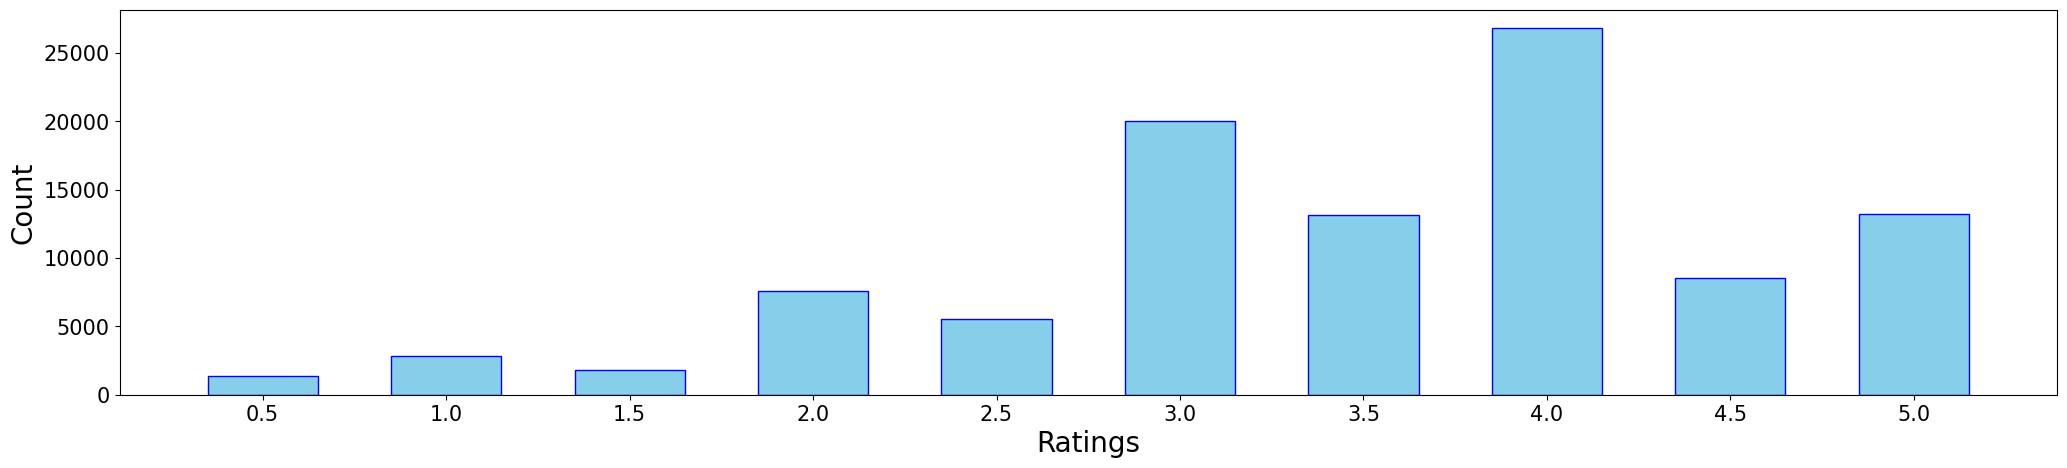

In [57]:
plt.figure(figsize = (25,5))
plt.bar(ratings_dis.index,ratings_dis.values,width = 0.3,color = "skyblue",edgecolor = "blue")
plt.xticks(ratings_dis.index,fontsize = 15)
plt.yticks(fontsize = 15)
plt.xlabel("Ratings",fontsize = 20)
plt.ylabel("Count",fontsize = 20)
plt.show()

In [58]:
import warnings
warnings.filterwarnings("ignore")

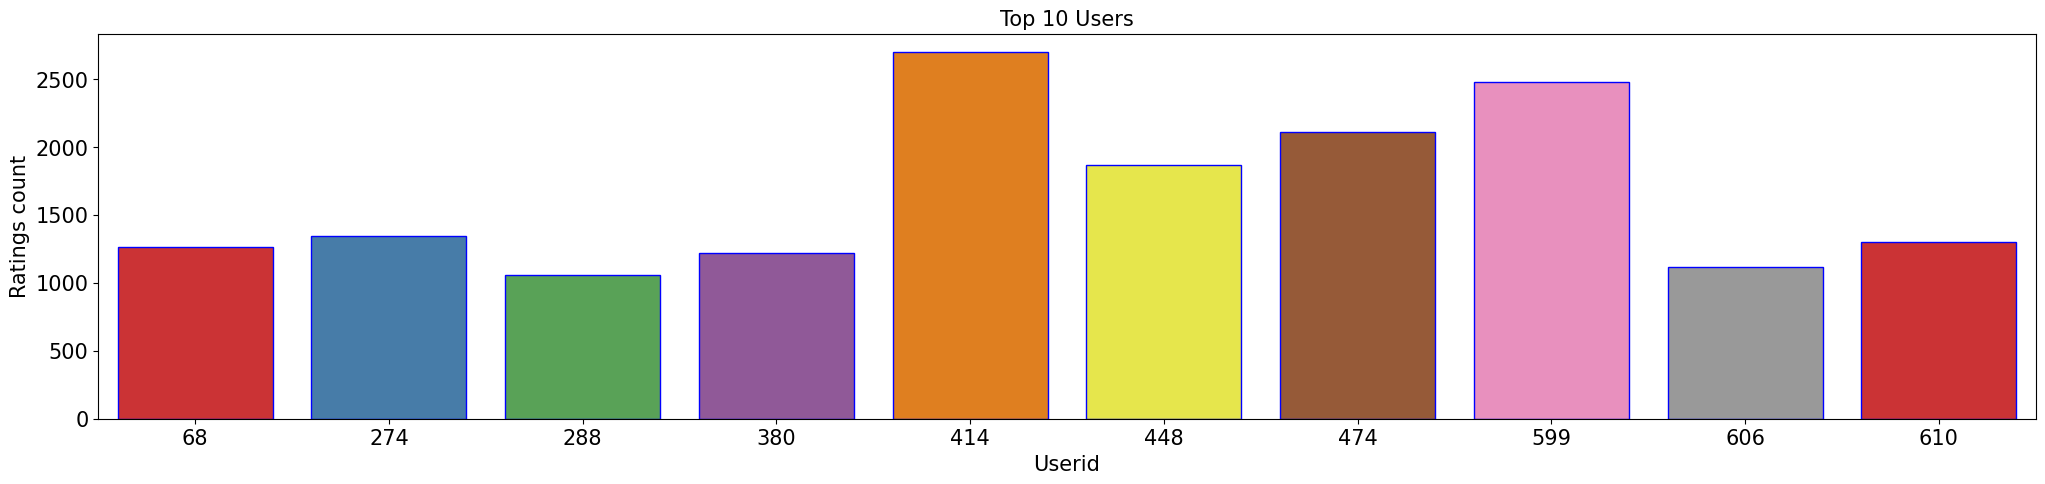

In [59]:
top_users = df["userId"].value_counts().head(10)
plt.figure(figsize = (25,5))
sns.barplot(x=top_users.index, y = top_users.values, palette ="Set1",edgecolor = "blue")
plt.xlabel("Userid",fontsize= 15)
plt.ylabel("Ratings count", fontsize =15)
plt.xticks(fontsize = 15)
plt.yticks(fontsize = 15)
plt.title("Top 10 Users",fontsize =15)
plt.show()

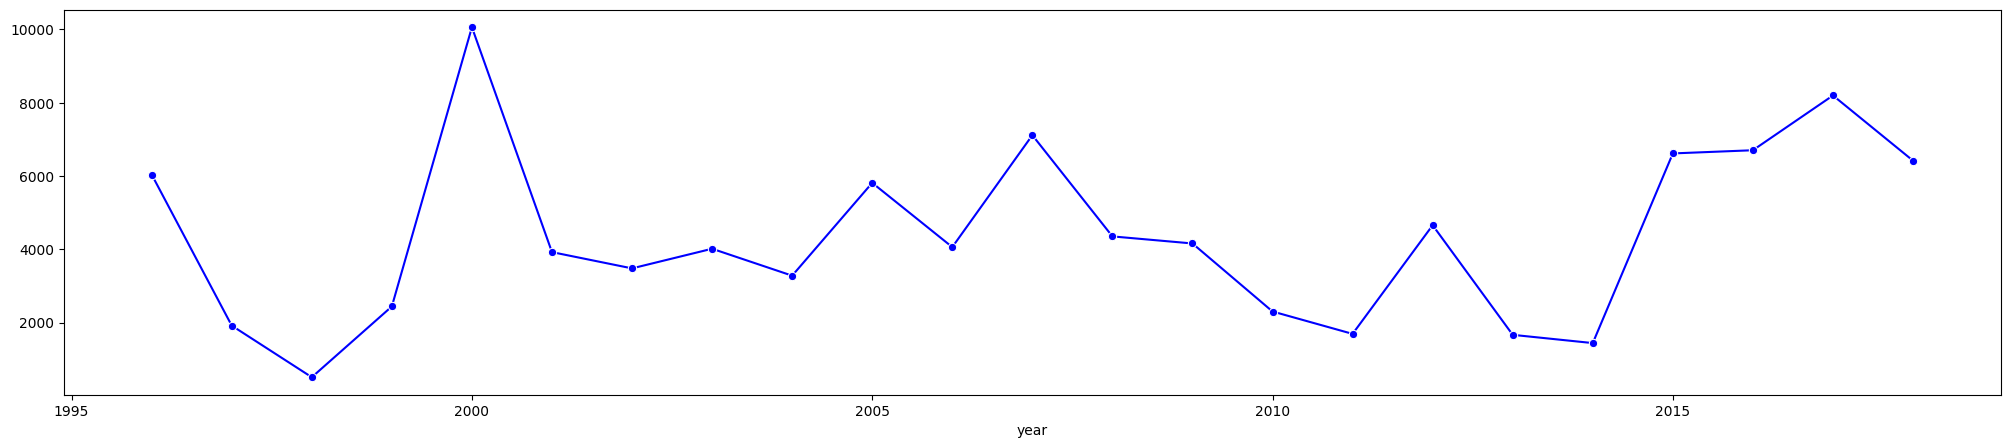

In [60]:
rating_years = df["year"].value_counts()
plt.figure(figsize= (25,5))
sns.lineplot(x = rating_years.index,y= rating_years.values,color = "blue",marker = "o")
plt.show()

In [66]:
df.head()

,movieId,title,genres,userId,rating,year,month,dayofweek,day,weekend,time_period
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1,4.0,2000,7,6,Sunday,Weekend,evening
1,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,5,4.0,1996,11,4,Friday,Weekday,morning
2,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,7,4.5,2005,1,1,Tuesday,Weekday,morning
3,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,15,2.5,2017,11,0,Monday,Weekday,afternoon
4,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,17,4.5,2011,5,2,Wednesday,Weekday,morning


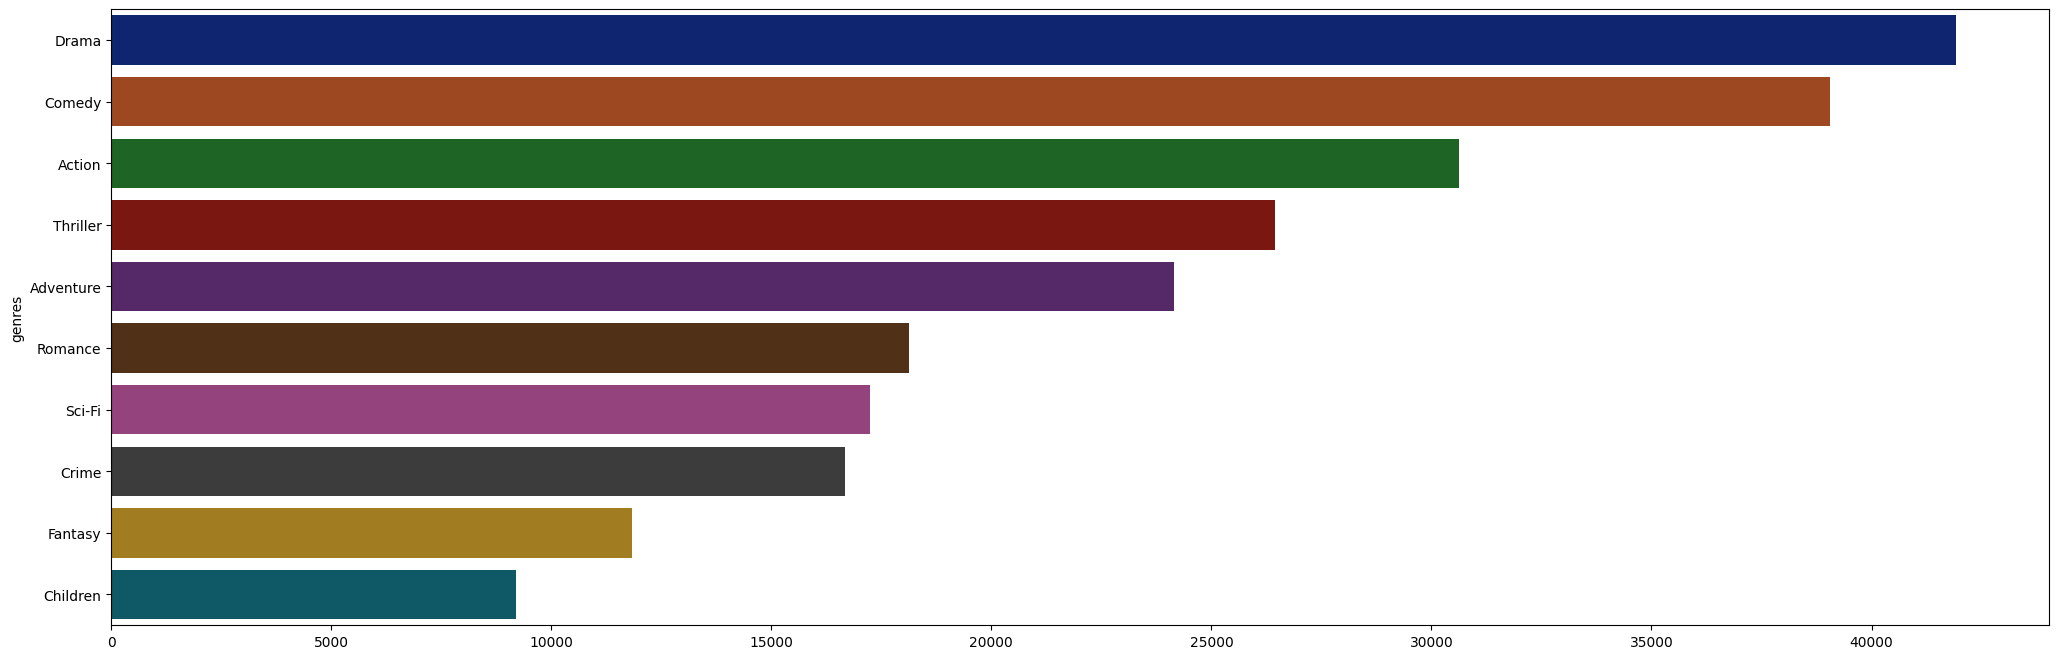

In [61]:
genres = df["genres"].str.split("|").explode().value_counts().head(10)
plt.figure(figsize = (25,8))
sns.barplot(x=genres.values, y=genres.index, hue=genres.index, palette="dark", legend=False)
plt.show()

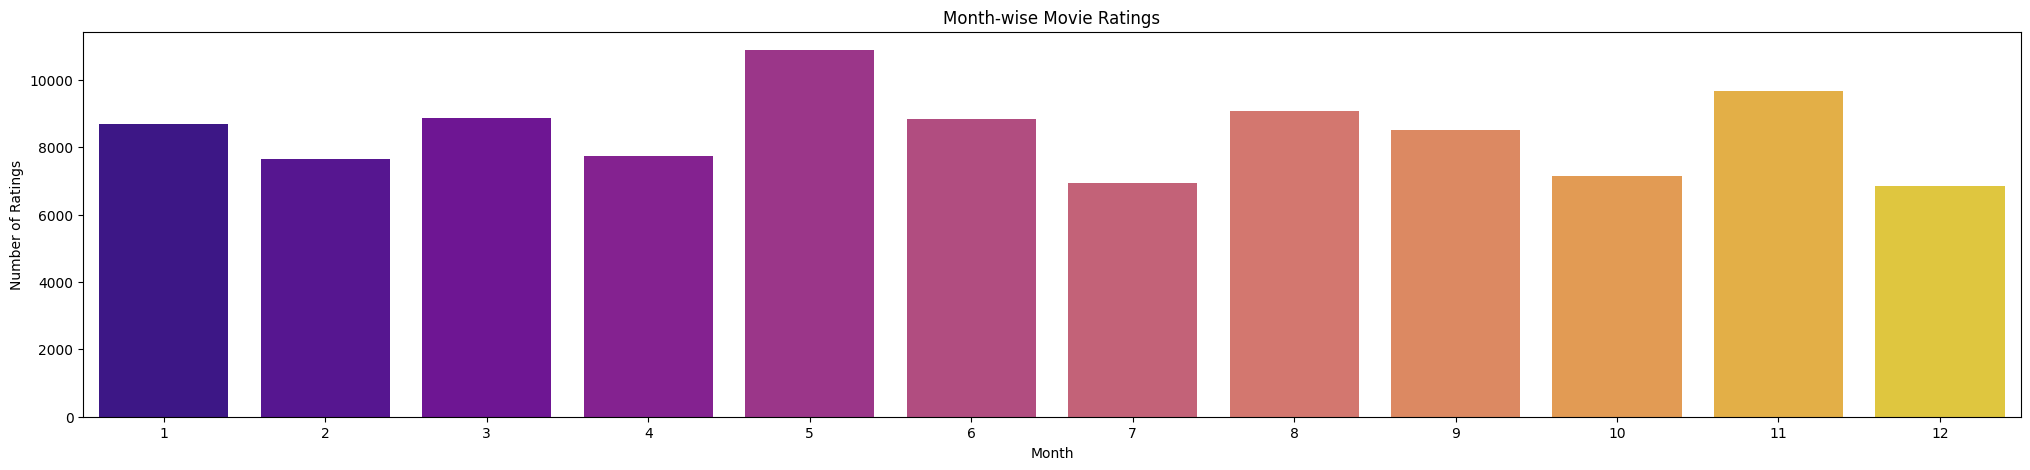

In [62]:
month_count = df["month"].value_counts().sort_index()

plt.figure(figsize=(25,5))
sns.barplot(x=month_count.index, y=month_count.values,palette = "plasma")
plt.title("Month-wise Movie Ratings")
plt.xlabel("Month")
plt.ylabel("Number of Ratings")
plt.show()

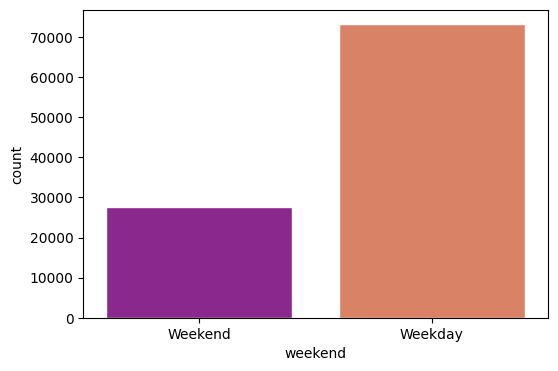

In [63]:
plt.figure(figsize = (6,4))
sns.countplot(data=df, x="weekend", hue="weekend", palette="plasma", edgecolor = "white")
plt.show()

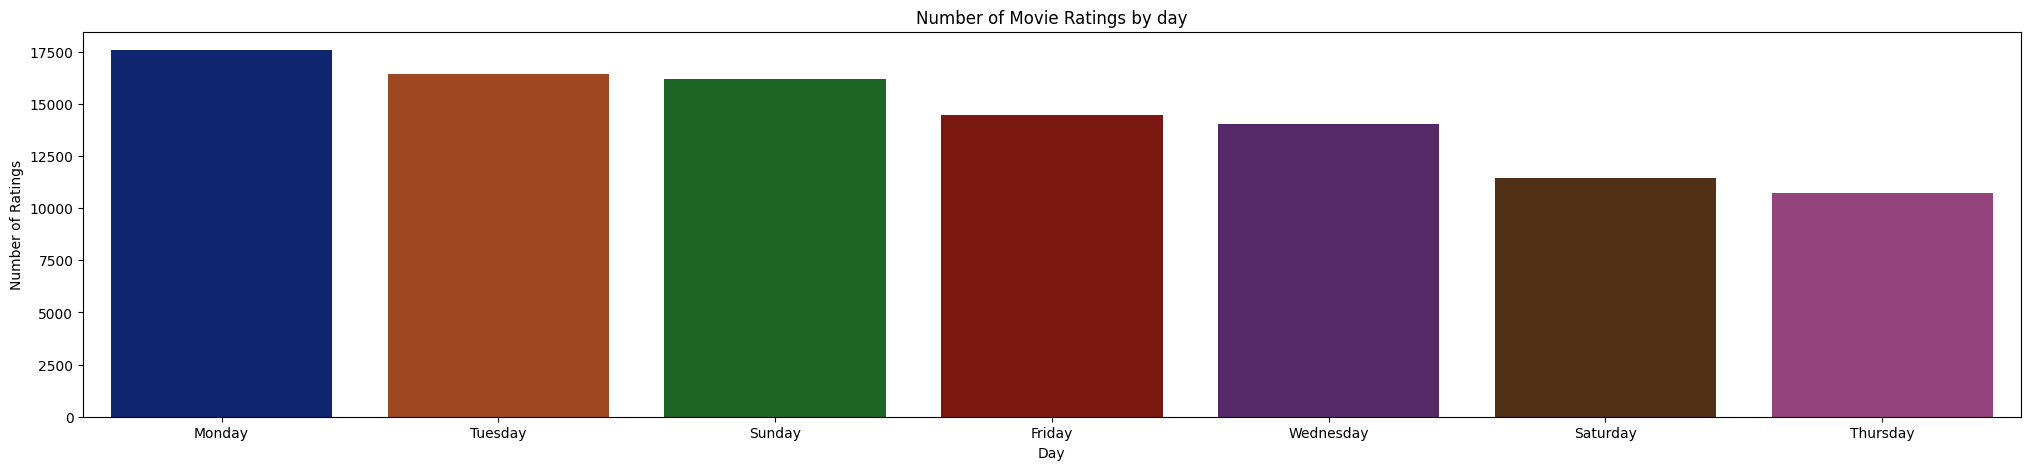

In [64]:
day_count = df["day"].value_counts()

plt.figure(figsize=(25,5))
sns.barplot(x=day_count.index, y=day_count.values, palette = "dark")
plt.title("Number of Movie Ratings by day")
plt.xlabel("Day")
plt.ylabel("Number of Ratings")
plt.show()

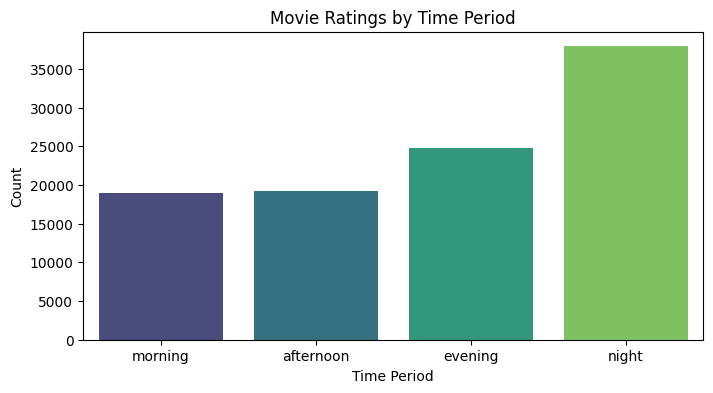

In [65]:
plt.figure(figsize=(8,4))

sns.countplot(data=df, x="time_period",order=["morning", "afternoon", "evening", "night"],palette = "viridis")
plt.title("Movie Ratings by Time Period")
plt.xlabel("Time Period")
plt.ylabel("Count")
plt.show()

# Final Conclusion

The MovieLens dataset analysis provides useful insights into user rating behaviour, movie preferences, and rating patterns.

1. **User Behaviour:** User ID 414 is the most active user, and weekdays receive significantly more ratings than weekends.

2. **Movie Preferences:** Drama, Comedy, and Action are the most popular genres.

3. **Rating Behaviour:** Most users give ratings between 3.0 and 5.0, showing generally positive movie feedback.

4. **Time Analysis:** Night is the most active time period, and Monday receives the highest number of ratings.

5. **Monthly Analysis:** May records the highest rating activity, while December records the lowest.

### Overall Conclusion

Overall, the analysis shows that users generally provide positive movie ratings, prefer genres like Drama and Comedy, and are most active in submitting ratings during nighttime and weekdays.